## 라이브러리 설치 & Import

In [22]:
#!pip install matplotlib

In [23]:
# 데이터 처리 및 분석
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import warnings

# 시각화
import matplotlib.pyplot as plt
import seaborn as sns

# 통계 분석
from scipy import stats
from scipy.stats import shapiro, levene, ttest_ind, chi2_contingency, f_oneway
from scipy.stats import mannwhitneyu, fisher_exact, kruskal
from statsmodels.stats.multicomp import pairwise_tukeyhsd, MultiComparison
import pingouin as pg

# 출력 설정
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# 한글 폰트 설정
import platform
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':  # maxOS
    plt.rcParams['font.family'] = 'AppleGothic'
else:  # Linux
    plt.rcParams['font.family'] = 'NanumGothic'
    
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (12, 6)

# 시드 설정
np.random.seed(42)

print("="*60)
print("라이브러리 로드 완료!")
print("한글 폰트 설정 완료!")
print("="*60)

라이브러리 로드 완료!
한글 폰트 설정 완료!


## 데이터 로드

In [24]:
# 데이터 로드
df_articles = pd.read_csv('./datasets/articles_hm.csv')
df_customer = pd.read_csv('./datasets/customer_hm.csv')
df_transaction = pd.read_csv('./datasets/transactions_hm.csv')

## 데이터 조회

In [25]:
df_transaction

,t_dat,customer_id,article_id,price,sales_channel_id
0,2019-11-05,3e2b60b679e62fb49516105b975560082922011dd752ec...,698328010,0.016932,2
1,2019-05-22,89647ac2274f54c770aaa4b326e0eea09610c252381f37...,760597002,0.033881,2
2,2019-05-10,2ebe392150feb60ca89caa8eff6c08b7ef1138cd6fdc71...,488561032,0.016932,2
3,2019-08-26,7b3205de4ca17a339624eb5e3086698e9984eba6b47c56...,682771001,0.033881,2
4,2019-08-10,3b77905de8b32045f08cedb79200cdfa477e9562429a39...,742400033,0.003220,1
...,...,...,...,...,...
1048570,2019-03-25,8e900818a1da0e73300a012794615993fbefb43f851430...,766346001,0.025407,2
1048571,2019-10-18,13aa106eeb8a6fa2f9e2ab888a3a2ee118a3900670f0d8...,811905001,0.016932,2
1048572,2019-04-06,5f51e21397c1248aafdf9712435bd4be063eb093f56229...,690108001,0.021729,2
1048573,2019-03-20,3421bd479ee13287a65660cf816b01d0d803d1d6d0fe73...,583534002,0.016932,2


#### 행, 열 개수 조회

In [26]:
print("데이터 모양(행, 열):", df_transaction.shape)

데이터 모양(행, 열): (1048575, 5)


#### 상위 5개, 하위 5개 데이터 조회

In [27]:
display(df_transaction.head())
display(df_transaction.tail())

,t_dat,customer_id,article_id,price,sales_channel_id
0,2019-11-05,3e2b60b679e62fb49516105b975560082922011dd752ec...,698328010,0.016932,2
1,2019-05-22,89647ac2274f54c770aaa4b326e0eea09610c252381f37...,760597002,0.033881,2
2,2019-05-10,2ebe392150feb60ca89caa8eff6c08b7ef1138cd6fdc71...,488561032,0.016932,2
3,2019-08-26,7b3205de4ca17a339624eb5e3086698e9984eba6b47c56...,682771001,0.033881,2
4,2019-08-10,3b77905de8b32045f08cedb79200cdfa477e9562429a39...,742400033,0.003220,1


,t_dat,customer_id,article_id,price,sales_channel_id
1048570,2019-03-25,8e900818a1da0e73300a012794615993fbefb43f851430...,766346001,0.025407,2
1048571,2019-10-18,13aa106eeb8a6fa2f9e2ab888a3a2ee118a3900670f0d8...,811905001,0.016932,2
1048572,2019-04-06,5f51e21397c1248aafdf9712435bd4be063eb093f56229...,690108001,0.021729,2
1048573,2019-03-20,3421bd479ee13287a65660cf816b01d0d803d1d6d0fe73...,583534002,0.016932,2
1048574,2019-01-13,5813663221b265eba9e4604e482be951d9a97ae022a88a...,554811018,0.011847,2


#### 컬럼명 조회

In [28]:
df_transaction.columns

Index(['t_dat', 'customer_id', 'article_id', 'price', 'sales_channel_id'], dtype='str')

#### 전체 구조 파악
- (행/열 개수, 컬럼별 데이터 타입, non-null 개수 조회)

In [29]:
df_transaction.info()

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   t_dat             1048575 non-null  str    
 1   customer_id       1048575 non-null  str    
 2   article_id        1048575 non-null  int64  
 3   price             1048575 non-null  float64
 4   sales_channel_id  1048575 non-null  int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 40.0 MB


#### 각 컬럼별 결측치 개수 확인

In [30]:
df_transaction.isna().sum()

t_dat               0
customer_id         0
article_id          0
price               0
sales_channel_id    0
dtype: int64

In [31]:
df_transaction['sales_channel_id'].value_counts()

sales_channel_id
2    729192
1    319383
Name: count, dtype: int64

#### 값의 분포, 통계치 확인
- (count, mean, std, min, 25%, 50%, 75%, max)

In [32]:
df_transaction.describe()

,article_id,price,sales_channel_id
count,1.048575e+06,1.048575e+06,1.048575e+06
mean,6.746672e+08,2.777915e-02,1.695412e+00
std,1.173503e+08,1.935764e-02,4.602328e-01
min,1.087750e+08,2.372880e-04,1.000000e+00
25%,6.289790e+08,1.523729e-02,1.000000e+00
50%,7.059880e+08,2.540678e-02,2.000000e+00
75%,7.500700e+08,3.388136e-02,2.000000e+00
max,8.797400e+08,5.067797e-01,2.000000e+00


#### Grain(식별 기준) 파악하기
- 식별자(Primary Key) 찾기
    - `id`, `code`, `no`

In [33]:
# 전체 행 개수
total_rows = len(df_transaction)
print(f"전체 행 개수: {total_rows}\n")

# ID로 추정되는 주요 컬럼들의 유일값 개수 확인
for col in df_transaction.columns:
    if 'id' in col.lower() or 'code' in col.lower() or 'no' in col.lower():
        unique_cnt = df_transaction[col].nunique()
        print(f"컬럼 [{col}]의 유일값 개수: {unique_cnt} (전체 행 대비 비중: {unique_cnt/total_rows*100:.1f}%)")

전체 행 개수: 1048575

컬럼 [customer_id]의 유일값 개수: 458235 (전체 행 대비 비중: 43.7%)
컬럼 [article_id]의 유일값 개수: 51279 (전체 행 대비 비중: 4.9%)
컬럼 [sales_channel_id]의 유일값 개수: 2 (전체 행 대비 비중: 0.0%)


#### 결측치 비율 파악

In [34]:
# 컬럼별 결측치 개수 및 비율 확인
null_PCT = pd.DataFrame({
    '결측치_개수': df_transaction.isnull().sum(),
    '결측치_비율(%)': (df_transaction.isnull().sum() / len(df_transaction) * 100).round(2)
})

# 결측치가 1개 이상 있는 컬럼만 출력
null_PCT[null_PCT['결측치_개수'] > 0]

,결측치_개수,결측치_비율(%)


#### 수치 기반 이상치 및 분포 확인

In [35]:
# 1. 수치형 컬럼 전체의 요약 통계량 확인
display(df_transaction.describe().T)

# 2. 수치형 컬럼만 자동 추출한 뒤, 전체 분위수(Quantile) 확인
numeric_df = df_transaction.select_dtypes(include=['number'])

# 수치형 컬럼이 1개라도 존재하는지 체크
if not numeric_df.empty:
    print("--- 모든 수치형 컬럼의 상세 분위수 확인 ---")
    # numeric_df 자체에 .quantile()을 적용하면 모든 수치형 컬럼이 한눈에 조회 가능
    display(numeric_df.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1.0]))
else:
    print("이 데이터에는 수치형 컬럼이 없습니다.")

,count,mean,std,min,25%,50%,75%,max
article_id,1048575.0,6.746672e+08,1.173503e+08,1.087750e+08,6.289790e+08,7.059880e+08,7.500700e+08,8.797400e+08
price,1048575.0,2.777915e-02,1.935764e-02,2.372880e-04,1.523729e-02,2.540678e-02,3.388136e-02,5.067797e-01
sales_channel_id,1048575.0,1.695412e+00,4.602328e-01,1.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00


--- 모든 수치형 컬럼의 상세 분위수 확인 ---


,article_id,price,sales_channel_id
0.01,189634001.0,0.003390,1.0
0.05,443860037.0,0.007475,1.0
0.25,628979002.0,0.015237,1.0
0.50,705988001.0,0.025407,2.0
0.75,750070001.0,0.033881,2.0
0.95,801384002.0,0.061000,2.0
0.99,829014002.0,0.101678,2.0
1.00,879740001.0,0.506780,2.0


#### 시각화를 활용한 이상치 탐색 (Boxplot)
- `가격('price')`

자동 추출된 수치형 컬럼 목록: ['price']


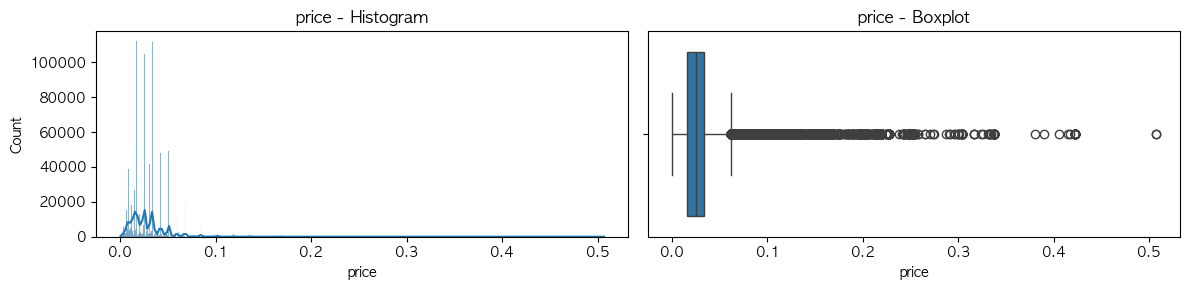

In [36]:
# 수치형 컬럼만 자동으로 추출 (ID처럼 의미 없는 숫자는 제외하고 싶다면 아래에서 자동 제거)
numeric_cols = df_transaction.select_dtypes(include=["number"]).columns.tolist()

# ID 관련 컬럼은 시각화에서 제외 (컬럼명에 'id'가 들어간 경우 자동 제외)
numeric_cols = [col for col in numeric_cols if "id" not in col.lower()]

print(f"자동 추출된 수치형 컬럼 목록: {numeric_cols}")

# 2. 추출된 수치형 컬럼들을 순회하며 자동으로 시각화
for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))

    # 왼쪽: 히스토그램 (분포 확인)
    sns.histplot(data=df_transaction, x=col, kde=True, ax=axes[0])
    axes[0].set_title(f"{col} - Histogram")

    # 오른쪽: 박스플롯 (이상치 및 쏠림 확인)
    sns.boxplot(data=df_transaction, x=col, ax=axes[1])
    axes[1].set_title(f"{col} - Boxplot")

    plt.tight_layout()
    plt.show()

In [37]:
# 1. 사분위수(Q1, Q3) 및 중위수 계산
q1 = df_transaction['price'].quantile(0.25)
q3 = df_transaction['price'].quantile(0.75)
median = df_transaction['price'].median()

# 2. IQR(Q3 - Q1) 및 박스플롯 상한선 계산
iqr = q3 - q1
upper_bound = q3 + (1.5 * iqr)

# 3. 이상치 개수 및 비율 확인 (선택사항)
outliers = df_transaction[df_transaction['price'] > upper_bound]
outlier_ratio = (len(outliers) / len(df_transaction)) * 100

print(f"Q1 (하위 25%): {q1:.3f}")
print(f"중위수 (50%): {median:.3f}")
print(f"Q3 (상위 25%): {q3:.3f}")
print(f"이상치 판단 상한선 (Q3 + 1.5*IQR): {upper_bound:.3f}")
print(f"이상치 비율: {outlier_ratio:.2f}%")

Q1 (하위 25%): 0.015
중위수 (50%): 0.025
Q3 (상위 25%): 0.034
이상치 판단 상한선 (Q3 + 1.5*IQR): 0.062
이상치 비율: 4.76%


#### 숨은 결측치 문자 체크

In [38]:
# 1. 범주형(문자형) 컬럼 목록 자동 추출
cat_cols = df_transaction.select_dtypes(include=['object', 'category']).columns

# 2. 체크하고 싶은 '숨은 결측치 문자' 목록
missing_indicators = ['Unknown', 'unknown', 'None', '-', '?']

print("=== 범주형 컬럼 내 텍스트 결측치 점검 결과 ===")

# 모든 범주형 컬럼을 돌면서 확인
for col in cat_cols:
    for indicator in missing_indicators:
        # 해당 문자가 들어있는 개수 세기
        count = (df_transaction[col] == indicator).sum()
        
        # 1개라도 발견되면 출력
        if count > 0:
            print(f"[{col}] 컬럼에 '{indicator}' 값이 {count}개 존재합니다.")

=== 범주형 컬럼 내 텍스트 결측치 점검 결과 ===


#### 오탈자 및 띄어쓰기 문제 확인

In [39]:
# 모든 범주형 컬럼에 대해 공백 문제 및 오탈자 가능성 점검
for col in cat_cols:
    original_nunique = df_transaction[col].nunique()
    
    # 양쪽 공백을 제거(.str.strip())했을 때의 종류 수 계산
    cleaned_nunique = df_transaction[col].astype(str).str.strip().nunique()
    
    if original_nunique != cleaned_nunique:
        print(f" [{col}] 컬럼: 띄어쓰기/공백 문제 존재")
        print(f"  - 원본 종류 수: {original_nunique}개 -> 공백 제거 후: {cleaned_nunique}개")

#### 클래스 불균형 (한 항목 99% 독점) 확인하기
- 분석 가치 없는 컬럼이라 삭제해야 함

In [40]:
print("=== 클래스 불균형 (특정 항목 95% 이상 독점) 점검 ===")

for col in cat_cols:
    # normalize=True를 주면 비율(0~1)로 나옴
    top_ratio = df_transaction[col].value_counts(normalize=True, dropna=False).iloc[0]
    top_value = df_transaction[col].value_counts(dropna=False).index[0]
    
    # 1등 항목이 전체의 95%(0.95) 이상을 차지하는 경우 경고 출력
    if top_ratio >= 0.95:
        print(f" [{col}] 컬럼: 클래스 불균형 존재")
        print(f"  - 가장 많은 값: '{top_value}' ({top_ratio*100:.1f}%)")

=== 클래스 불균형 (특정 항목 95% 이상 독점) 점검 ===


#### 중복 데이터 조회 및 처리

In [41]:
# 전체 테이블에서 완전히 똑같은 중복 행이 몇 개 있는지 확인
print("완전 중복 행 개수:", df_transaction.duplicated().sum())

# 중복 데이터만 뽑아서 customer_id, t_dat 순으로 정렬해서 보기
duplicate_rows = df_transaction[df_transaction.duplicated(keep=False)]
display(duplicate_rows.sort_values(by=['customer_id', 't_dat']).head(10))

완전 중복 행 개수: 8474


,t_dat,customer_id,article_id,price,sales_channel_id
63435,2019-01-06,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,536933002,0.016932,2
772023,2019-01-06,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,536933002,0.016932,2
304033,2019-04-24,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,778075001,0.040661,2
571052,2019-04-24,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,778075001,0.040661,2
318566,2019-01-27,0006b5856381fac4eac03efe68a6578a2d9260f4e109f4...,497284015,0.022017,2
965701,2019-01-27,0006b5856381fac4eac03efe68a6578a2d9260f4e109f4...,497284015,0.022017,2
200234,2019-03-06,0008d30a148478dc88c69af6c51230ad5802590afc8488...,728197002,0.042356,2
638438,2019-03-06,0008d30a148478dc88c69af6c51230ad5802590afc8488...,728197002,0.042356,2
418128,2019-02-22,001021122bdb55ec4235f35eb50164c268ec7c4bcfff90...,756771002,0.021593,2
446554,2019-02-22,001021122bdb55ec4235f35eb50164c268ec7c4bcfff90...,756771002,0.021593,2


### 수치 간 상관관계 히트맵

In [44]:
# 수치형 컬럼 추출
numeric_cols = df_transaction.select_dtypes(include=["number"]).columns.tolist()

# _id, _code, _no 가 들어간 컬럼을 '대소문자 구분 없이' 제거
clean_numeric_cols = [col for col in numeric_cols
    if not any(k in col.lower() for k in ["id", "code", "no"])]

print("제거 후 남아있는 진짜 수치형 컬럼 목록:", clean_numeric_cols)

# 남아있는 수치형 컬럼이 2개 이상일 때만 히트맵 실행
if len(clean_numeric_cols) >= 2:
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        df_transaction[clean_numeric_cols].corr(),
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
    )
    plt.title("Correlation Heatmap")
    plt.show()
else:
    print(
        "\n 확인 완료: ID/코드성 번호를 제외하면 진짜 숫자(가격, 수량 등) 변수가 존재하지 않습니다."
    )

제거 후 남아있는 진짜 수치형 컬럼 목록: ['price']

 확인 완료: ID/코드성 번호를 제외하면 진짜 숫자(가격, 수량 등) 변수가 존재하지 않습니다.


#### 범주형 변수 비중 확인

In [47]:
# 글자(범주형) 컬럼만 추출
cat_cols = df_transaction.select_dtypes(include=["object", "category"]).columns.tolist()

# 고유값(종류)이 너무 많은 컬럼(예: 30개 초과) 및 ID/설명 컬럼 자동 제외
filtered_cat_cols = [col for col in cat_cols
    if df_transaction[col].nunique() <= 30  # 카테고리 종류가 30개 이하인 것만 선별
    and not any(k in col.lower() for k in ["id", "code", "no", "desc", "name_length"])]

print("시각화에 적합한 범주형 컬럼 목록:", filtered_cat_cols)

# 선별된 진짜 범주형 컬럼들만 countplot 그리기
for col in filtered_cat_cols:
    plt.figure(figsize=(15, 4))
    # 데이터 상위 10개만 골라 시각화
    top_10 = df_transaction[col].value_counts().head(10).index
    sns.countplot(
        data=df_transaction[df_transaction[col].isin(top_10)],
        y=col,
        order=top_10,)
    
    ax = sns.countplot(
        data=df_transaction[df_transaction[col].isin(top_10)],
        y=col,
        order=top_10,)
    
    ax.bar_label(ax.containers[0], fmt="%d", padding=3)

    plt.title(f"{col} - Top 10 Countplot")
    plt.xlabel("Count")
    plt.show()

시각화에 적합한 범주형 컬럼 목록: []


#### 범주형 데이터 고유값 빈도수(개수) 확인(결측치 제외)

In [49]:
# 제외할 컬럼 목록 직접 지정 (detail_desc, customer_id 등)
exclude_cols = ['detail_desc', 'customer_id']

# 범주형 컬럼 중 제외 목록만 빼고 선택
categorical_cols = [c for c in df_transaction.select_dtypes(include=['object', 'category']).columns if c not in exclude_cols]

# 고유값 빈도 및 비율 출력
for col in categorical_cols:
    print(f"=== {col} ===")
    counts = df_transaction[col].value_counts()  # dropna=True (기본값)
    probs = df_transaction[col].value_counts(normalize=True) * 100
    
    summary = pd.DataFrame({'Count': counts, 'Percentage (%)': probs.round(2)})
    display(summary)
    print("\n")

=== t_dat ===


,Count,Percentage (%)
t_dat,,
2019-09-28,12860,1.23
2019-11-29,10340,0.99
2019-07-24,8054,0.77
2019-04-06,7547,0.72
2019-11-28,6782,0.65
...,...,...
2019-12-03,1479,0.14
2019-09-21,1374,0.13
2019-12-26,1266,0.12
